<a href="https://colab.research.google.com/github/aishakhushbu/Drug-pathogen-project-/blob/main/BBB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Research question**
Can conventional molecular properties distinguish drugs that penetrate the blood brain barrier (BBB) from those that show limited or no peneration, and what characteristics are associated with compounds that are incorrectly classified

**Hypothesis**

BBB- penetration drugs will generally exhibit a combination of physicochemical characteristics associated with membrane permeability,such as lower polar surface area and moderate lipophilicity but thee properties alone will not reliably classify every drug

In [ ]:
pip -q install rdkit pandas numpy matplotlib seaborn scikit-learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [ ]:
df = pd.read_csv("bbb_drugs.csv")

df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'bbb_drugs.csv'

In [ ]:
from rdkit import Chem
mol = Chem.MolFromSmiles("CCO") #ethanol
print(mol is not None)

True


In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/theochem/B3DB/main/B3DB/B3DB_classification.tsv"

b3db = pd.read_csv(url, sep="\t")

print("Shape:", b3db.shape)
print("Columns:")
print(b3db.columns.tolist())

Shape: (7807, 12)
Columns:
['NO.', 'compound_name', 'IUPAC_name', 'SMILES', 'CID', 'logBB', 'BBB+/BBB-', 'Inchi', 'threshold', 'reference', 'group', 'comments']


In [ ]:
b3db.head()

,NO.,compound_name,IUPAC_name,SMILES,CID,logBB,BBB+/BBB-,Inchi,threshold,reference,group,comments
0,1,sulphasalazine,2-hydroxy-5-[[4-(pyridin-2-ylsulfamoyl)phenyl]...,O=C(O)c1cc(N=Nc2ccc(S(=O)(=O)Nc3ccccn3)cc2)ccc1O,5339.0,-2.69,BBB-,InChI=1S/C18H14N4O5S/c23-16-9-6-13(11-15(16)18...,NaN,R2|R2|R25|R46|,A,NaN
1,2,moxalactam,7-[[2-carboxy-2-(4-hydroxyphenyl)acetyl]amino]...,COC1(NC(=O)C(C(=O)O)c2ccc(O)cc2)C(=O)N2C(C(=O)...,3889.0,-2.52,BBB-,InChI=1S/C20H20N6O9S/c1-25-19(22-23-24-25)36-8...,NaN,R25|,A,NaN
2,3,clioquinol,5-chloro-7-iodoquinolin-8-ol,Oc1c(I)cc(Cl)c2cccnc12,2788.0,-2.40,BBB-,InChI=1S/C9H5ClINO/c10-6-4-7(11)9(13)8-5(6)2-1...,NaN,R18|R26|R27|,A,NaN
3,4,bbcpd11 (cimetidine analog) (y-g13),2-[2-[(3-bromopyridin-2-yl)methylsulfanyl]ethy...,CCNC(=NCCSCc1ncccc1Br)NC#N,14022517.0,-2.15,BBB-,InChI=1S/C12H16BrN5S/c1-2-15-12(18-9-14)17-6-7...,NaN,R2|R2|R8|R40|R2|R2|R2|R2|R18|R21|R25|R25|R26|R...,A,NaN
4,5,schembl614298,"(2s,3s,4s,5r)-6-[[(4r,4ar,7s,7ar,12bs)-7-hydro...",CN1CC[C@]23c4c5ccc(OC6O[C@H](C(=O)O)[C@@H](O)[...,18595497.0,-2.15,BBB-,InChI=1S/C23H27NO9/c1-24-7-6-23-10-3-4-12(25)2...,NaN,R25|,A,NaN


In [ ]:
print("Number of compounds:", len(b3db))

print("\nBBB classification:")
print(b3db["BBB+/BBB-"].value_counts())

print("\nMissing values:")
print(b3db[["compound_name", "SMILES", "BBB+/BBB-"]].isna().sum())

Number of compounds: 7807

BBB classification:
BBB+/BBB-
BBB+    4956
BBB-    2851
Name: count, dtype: int64

Missing values:
compound_name    1109
SMILES              0
BBB+/BBB-           0
dtype: int64


In [ ]:
b3db["compound_name"].head(30).tolist()

['sulphasalazine',
 'moxalactam',
 'clioquinol',
 'bbcpd11 (cimetidine analog) (y-g13)',
 'schembl614298',
 'uk-240,455',
 'morphine-6-glucuronide',
 'nitrofurantoin',
 'l-701,324',
 '33419-42-0',
 'icotidine',
 'ro 64-0802',
 'temelastine',
 'disodium;(6r,7s)-7-[[4-(2-amino-1-carboxylato-2-oxoethylidene)-1,3-dithietane-2-carbonyl]amino]-7-methoxy-3-[(1-methyltetrazol-5-yl)sulfanylmethyl]-8-oxo-5-thia-1-azabicyclo[4.2.0]oct-2-ene-2-carboxylate',
 'cefotetan',
 '1848-75-5',
 '2-[4-(5-bromo-3-methylpyridin-2-yl)butylamino]-5-[(6-methylpyridin-3-yl)methyl]-1,3-diazinan-4-one',
 'm2l-663581',
 'ritonavir',
 'bis-hydroxylated-l-663581',
 nan,
 nan,
 'raloxifene',
 'telmesteine',
 'chlorambucil',
 'quercetin',
 'sucrose',
 'flurbiprofen',
 'schembl18285121',
 'd-mannitol']

In [ ]:
print("Missing compound names:", b3db["compound_name"].isna().sum())
print("Missing SMILES:", b3db["SMILES"].isna().sum())
print("Missing BBB labels:", b3db["BBB+/BBB-"].isna().sum())
print("Missing logBB:", b3db["logBB"].isna().sum())

Missing compound names: 1109
Missing SMILES: 0
Missing BBB labels: 0
Missing logBB: 6749


In [ ]:
name_counts = b3db["compound_name"].value_counts()

print("Names appearing more than once:")
print(name_counts[name_counts > 1].head(30))

Names appearing more than once:
compound_name
-                 7
aztreonam         7
morphine          7
ribavirin         6
ketoconazole      6
digoxin           6
quinidine         6
cefpodoxime       5
carumonam         5
ceftizoxime       5
itraconazole      5
josamycin         5
cefditoren        5
plicamycin        5
rifapentine       5
rifabutin         5
rifaximin         5
oxycodone         5
azithromycin      5
ritonavir         5
buprenorphine     5
teniposide        5
oxacillin         5
cefdinir          5
ketazocine        5
vinblastine       5
hydrocodone       5
rifamexil         4
hydrocortamate    4
demecycline       4
Name: count, dtype: int64


In [ ]:
b3db.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7807 entries, 0 to 7806
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   NO.            7807 non-null   int64  
 1   compound_name  6698 non-null   object 
 2   IUPAC_name     6170 non-null   object 
 3   SMILES         7807 non-null   object 
 4   CID            6170 non-null   float64
 5   logBB          1058 non-null   float64
 6   BBB+/BBB-      7807 non-null   object 
 7   Inchi          7807 non-null   object 
 8   threshold      3621 non-null   float64
 9   reference      7807 non-null   object 
 10  group          7807 non-null   object 
 11  comments       18 non-null     object 
dtypes: float64(3), int64(1), object(8)
memory usage: 732.0+ KB


In [ ]:
b3db.head()

,NO.,compound_name,IUPAC_name,SMILES,CID,logBB,BBB+/BBB-,Inchi,threshold,reference,group,comments
0,1,sulphasalazine,2-hydroxy-5-[[4-(pyridin-2-ylsulfamoyl)phenyl]...,O=C(O)c1cc(N=Nc2ccc(S(=O)(=O)Nc3ccccn3)cc2)ccc1O,5339.0,-2.69,BBB-,InChI=1S/C18H14N4O5S/c23-16-9-6-13(11-15(16)18...,NaN,R2|R2|R25|R46|,A,NaN
1,2,moxalactam,7-[[2-carboxy-2-(4-hydroxyphenyl)acetyl]amino]...,COC1(NC(=O)C(C(=O)O)c2ccc(O)cc2)C(=O)N2C(C(=O)...,3889.0,-2.52,BBB-,InChI=1S/C20H20N6O9S/c1-25-19(22-23-24-25)36-8...,NaN,R25|,A,NaN
2,3,clioquinol,5-chloro-7-iodoquinolin-8-ol,Oc1c(I)cc(Cl)c2cccnc12,2788.0,-2.40,BBB-,InChI=1S/C9H5ClINO/c10-6-4-7(11)9(13)8-5(6)2-1...,NaN,R18|R26|R27|,A,NaN
3,4,bbcpd11 (cimetidine analog) (y-g13),2-[2-[(3-bromopyridin-2-yl)methylsulfanyl]ethy...,CCNC(=NCCSCc1ncccc1Br)NC#N,14022517.0,-2.15,BBB-,InChI=1S/C12H16BrN5S/c1-2-15-12(18-9-14)17-6-7...,NaN,R2|R2|R8|R40|R2|R2|R2|R2|R18|R21|R25|R25|R26|R...,A,NaN
4,5,schembl614298,"(2s,3s,4s,5r)-6-[[(4r,4ar,7s,7ar,12bs)-7-hydro...",CN1CC[C@]23c4c5ccc(OC6O[C@H](C(=O)O)[C@@H](O)[...,18595497.0,-2.15,BBB-,InChI=1S/C23H27NO9/c1-24-7-6-23-10-3-4-12(25)2...,NaN,R25|,A,NaN


In [ ]:
b3db["BBB"].value_counts()

KeyError: 'BBB'

In [ ]:
# Create a copy of the original B3DB dataset
study = b3db.copy()

# keep records with a name, SMILES, and BBB classification
study = study[
    study["compound_name"].notna()   &
    study["SMILES"].notna() &
    study["BBB+/BBB-"].notna()
].copy()

print("Usable records:", len(study))
study[["compound_name", "SMILES", "BBB+/BBB-"]].head()

Usable records: 6698


,compound_name,SMILES,BBB+/BBB-
0,sulphasalazine,O=C(O)c1cc(N=Nc2ccc(S(=O)(=O)Nc3ccccn3)cc2)ccc1O,BBB-
1,moxalactam,COC1(NC(=O)C(C(=O)O)c2ccc(O)cc2)C(=O)N2C(C(=O)...,BBB-
2,clioquinol,Oc1c(I)cc(Cl)c2cccnc12,BBB-
3,bbcpd11 (cimetidine analog) (y-g13),CCNC(=NCCSCc1ncccc1Br)NC#N,BBB-
4,schembl614298,CN1CC[C@]23c4c5ccc(OC6O[C@H](C(=O)O)[C@@H](O)[...,BBB-


In [ ]:
study["compound_name"].head(50).tolist()

['sulphasalazine',
 'moxalactam',
 'clioquinol',
 'bbcpd11 (cimetidine analog) (y-g13)',
 'schembl614298',
 'uk-240,455',
 'morphine-6-glucuronide',
 'nitrofurantoin',
 'l-701,324',
 '33419-42-0',
 'icotidine',
 'ro 64-0802',
 'temelastine',
 'disodium;(6r,7s)-7-[[4-(2-amino-1-carboxylato-2-oxoethylidene)-1,3-dithietane-2-carbonyl]amino]-7-methoxy-3-[(1-methyltetrazol-5-yl)sulfanylmethyl]-8-oxo-5-thia-1-azabicyclo[4.2.0]oct-2-ene-2-carboxylate',
 'cefotetan',
 '1848-75-5',
 '2-[4-(5-bromo-3-methylpyridin-2-yl)butylamino]-5-[(6-methylpyridin-3-yl)methyl]-1,3-diazinan-4-one',
 'm2l-663581',
 'ritonavir',
 'bis-hydroxylated-l-663581',
 'raloxifene',
 'telmesteine',
 'chlorambucil',
 'quercetin',
 'sucrose',
 'flurbiprofen',
 'schembl18285121',
 'd-mannitol',
 'mannitol (d-mannitol)',
 'compound 34',
 'y22',
 'l4',
 'chebi: 145922',
 'guanidinothiazol analogue 17 ac1lbibi -- pubmed',
 'cube-2',
 'cube-6',
 'cube-10',
 'chembl151192',
 'amethopterin',
 'rifampicin',
 'baclofen',
 'etoposide

In [ ]:
print(study["BBB+/BBB-"].value_counts())

BBB+/BBB-
BBB+    4319
BBB-    2379
Name: count, dtype: int64


In [ ]:
# Install the ChEMBL_websource_client
!pip -q install ChEMBL_websource_client

from chembl_websource_client.new_client import new_client
import pandas as pd
import re

#1. Get approved small-molecule drugs from ChEMBL
molecule = new_client.molecule

approved = molecule.filter(
    max_phase=4,
    molecule_type="Small Molecule"
).only([
    "molecule_chembl_id",
    "pref_name",
    "max_phase"
])

approved_rows = []

for x in approved:
    if x.get("pref_name"):
      approved_rows.append({
          "chembl_id": x["molecule_chembl_id"],
          "approved_name": x["pref_name"]
      })

approved_df = pd.DataFrame(approved_rows)

print("Approved ChEMBL compounds:", len(approved_df))


# 2. Normalize names so simple spelling/capitalization differences
# don't prevent matching
def normalize_name(x):
    if pd.isna(x):
         return ""
    x = str(x).lower().strip()
    x = x.replace("-", "", x)
    x = re.sub(r"[^a-z0-9]", "", x)
    x = re.sub(r"\s+", " ", x)
    return x

study["name_key"] = study["compound_name"].apply(normalize_name)
approved_df["name_key"] = approved_df["approved_name"].apply(normalize_name)

#3. Match B3DB compounds to approved drugs
candidate = study.merge(
    approved_df,
    on="name_key",
    how="inner"
)


# 4. Remove repeated records for now
candidate = candidate.drop_duplicates(
    subset=["compound_name", "SMILES", "BBB+/BBB-"]
)


#5. Show the candidate list
candidate_list = candidate[
    ["compound_name", "BBB+/BBB-", "SMILES", "logBB", "chembl_id"]
].sort_values("compound_name")


print("Candidate records:", len(candidate_list))
candidate_list.head(100)

ERROR: Could not find a version that satisfies the requirement ChEMBL_websource_client (from versions: none)
ERROR: No matching distribution found for ChEMBL_websource_client


ModuleNotFoundError: No module named 'chembl_websource_client'

In [ ]:
# Check the BBB dataset
print(b3db.shape)
print(b3db[["SMILES", "BBB+/BBB-", "logBB"]].head())

(7807, 12)
                                              SMILES BBB+/BBB-  logBB
0   O=C(O)c1cc(N=Nc2ccc(S(=O)(=O)Nc3ccccn3)cc2)ccc1O      BBB-  -2.69
1  COC1(NC(=O)C(C(=O)O)c2ccc(O)cc2)C(=O)N2C(C(=O)...      BBB-  -2.52
2                             Oc1c(I)cc(Cl)c2cccnc12      BBB-  -2.40
3                         CCNC(=NCCSCc1ncccc1Br)NC#N      BBB-  -2.15
4  CN1CC[C@]23c4c5ccc(OC6O[C@H](C(=O)O)[C@@H](O)[...      BBB-  -2.15


In [ ]:
from rdkit import Chem
from rdkit.Chem import Descriptors,Crippen, Lipinski, rdMolDescriptors

def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
       return pd.Series([None]*8)

    return pd.Series([
        Descriptors.MolWt(mol),
        Crippen.MolLogP(mol),
        rdMolDescriptors.CalcTPSA(mol),
        Lipinski.NumHDonors(mol),
        Lipinski.NumHAcceptors(mol),
        Lipinski.NumRotatableBonds(mol),
        rdMolDescriptors.CalcNumAromaticRings(mol),
        rdMolDescriptors.CalcFractionCSP3(mol)
    ])

descriptor_names = [
    "MW", "LogpP", "TPSA", "HBD",
    "HBA", "RotB", "AromaticRings", "FractionCSP3"
]

b3db[descriptor_names] = b3db["SMILES"].apply(calculate_descriptors)

b3db.head()

[13:33:49] Explicit valence for atom # 10 C, 4, is greater than permitted
[13:33:53] Explicit valence for atom # 10 C, 4, is greater than permitted


,NO.,compound_name,IUPAC_name,SMILES,CID,logBB,BBB+/BBB-,Inchi,threshold,reference,group,comments,MW,LogpP,TPSA,HBD,HBA,RotB,AromaticRings,FractionCSP3
0,1,sulphasalazine,2-hydroxy-5-[[4-(pyridin-2-ylsulfamoyl)phenyl]...,O=C(O)c1cc(N=Nc2ccc(S(=O)(=O)Nc3ccccn3)cc2)ccc1O,5339.0,-2.69,BBB-,InChI=1S/C18H14N4O5S/c23-16-9-6-13(11-15(16)18...,NaN,R2|R2|R25|R46|,A,NaN,398.400,3.70160,141.31,3.0,7.0,6.0,3.0,0.000000
1,2,moxalactam,7-[[2-carboxy-2-(4-hydroxyphenyl)acetyl]amino]...,COC1(NC(=O)C(C(=O)O)c2ccc(O)cc2)C(=O)N2C(C(=O)...,3889.0,-2.52,BBB-,InChI=1S/C20H20N6O9S/c1-25-19(22-23-24-25)36-8...,NaN,R25|,A,NaN,520.480,-1.12770,206.30,4.0,11.0,9.0,2.0,0.350000
2,3,clioquinol,5-chloro-7-iodoquinolin-8-ol,Oc1c(I)cc(Cl)c2cccnc12,2788.0,-2.40,BBB-,InChI=1S/C9H5ClINO/c10-6-4-7(11)9(13)8-5(6)2-1...,NaN,R18|R26|R27|,A,NaN,305.502,3.19840,33.12,1.0,2.0,0.0,2.0,0.000000
3,4,bbcpd11 (cimetidine analog) (y-g13),2-[2-[(3-bromopyridin-2-yl)methylsulfanyl]ethy...,CCNC(=NCCSCc1ncccc1Br)NC#N,14022517.0,-2.15,BBB-,InChI=1S/C12H16BrN5S/c1-2-15-12(18-9-14)17-6-7...,NaN,R2|R2|R8|R40|R2|R2|R2|R2|R18|R21|R25|R25|R26|R...,A,NaN,342.266,2.11348,73.10,2.0,4.0,6.0,1.0,0.416667
4,5,schembl614298,"(2s,3s,4s,5r)-6-[[(4r,4ar,7s,7ar,12bs)-7-hydro...",CN1CC[C@]23c4c5ccc(OC6O[C@H](C(=O)O)[C@@H](O)[...,18595497.0,-2.15,BBB-,InChI=1S/C23H27NO9/c1-24-7-6-23-10-3-4-12(25)2...,NaN,R25|,A,NaN,461.467,-1.23650,149.15,5.0,9.0,3.0,1.0,0.608696


In [ ]:
descriptor_cols = [
    "MW",
    "LogpP",
    "TPSA",
    "HBD",
    "RotB",
    "AromaticRings",
    "FractionCSP3"
]

summary = b3db.groupby("BBB+/BBB-")[descriptor_cols].median().T

summary

BBB+/BBB-,BBB+,BBB-
MW,330.4845,424.534000
LogpP,2.9233,1.458200
TPSA,54.0300,115.060000
HBD,1.0000,3.000000
RotB,4.0000,6.000000
AromaticRings,1.0000,1.000000
FractionCSP3,0.5000,0.461538


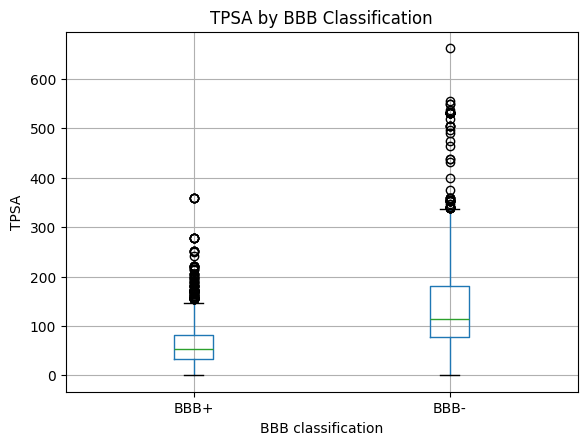

In [ ]:
import matplotlib.pyplot as plt

b3db.boxplot(
    column="TPSA",
    by="BBB+/BBB-"
)

plt.title("TPSA by BBB Classification")
plt.suptitle("")
plt.xlabel("BBB classification")
plt.ylabel("TPSA")
plt.show()

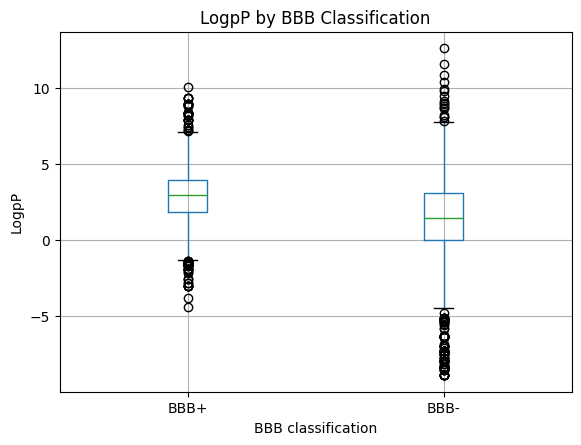

In [ ]:
b3db.boxplot(column="LogpP", by="BBB+/BBB-")

plt.title("LogpP by BBB Classification")
plt.suptitle("")
plt.xlabel("BBB classification")
plt.ylabel("LogpP")
plt.show()

In [ ]:
descriptor_cols = [
    "MW",
    "LogpP",
    "TPSA",
    "HBD",
    "HBA",
    "RotB",
    "AromaticRings",
    "FractionCSP3"
]

summary = b3db.groupby("BBB+/BBB-")[descriptor_cols].median().T
summary

BBB+/BBB-,BBB+,BBB-
MW,330.4845,424.534000
LogpP,2.9233,1.458200
TPSA,54.0300,115.060000
HBD,1.0000,3.000000
HBA,4.0000,6.000000
RotB,4.0000,6.000000
AromaticRings,1.0000,1.000000
FractionCSP3,0.5000,0.461538


In [ ]:
from scipy.stats import mannwhitneyu

for col in descriptor_cols:
  bbb_pos = b3db.loc[b3db["BBB+/BBB-"] ==  "BBB+",col].dropna()
  bbb_neg = b3db.loc[b3db["BBB+/BBB-"] == "BBB-", col].dropna()

  stat, p = mannwhitneyu(bbb_pos, bbb_neg, alternative="two-sided")

  print(f"{col}: p = {p:3e}")

MW: p = 5.044462e-197
LogpP: p = 1.411505e-157
TPSA: p = 0.000000e+00
HBD: p = 0.000000e+00
HBA: p = 0.000000e+00
RotB: p = 4.870441e-184
AromaticRings: p = 1.651424e-04
FractionCSP3: p = 2.210057e-02


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report,roc_auc_score

model_data = b3db.dropna(
   subset=descriptor_cols + ["BBB+/BBB-"]
).copy()

X = model_data[descriptor_cols]
y = (model_data["BBB+/BBB-"] == "BBB+").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)


model = Pipeline([
    ("Scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

              precision    recall  f1-score   support

           0       0.81      0.59      0.68       570
           1       0.80      0.92      0.85       991

    accuracy                           0.80      1561
   macro avg       0.80      0.76      0.77      1561
weighted avg       0.80      0.80      0.79      1561

ROC-AUC: 0.8280993856993644


In [ ]:
results = model_data.loc[X_test.index].copy()

results["Actual"] = y_test
results["Predicted"] = y_pred
results["BBB_probability"] = y_prob

results["Error"] = results["Actual"] != results["Predicted"]

results[["compound_name", "BBB+/BBB-", "Actual","Predicted", "BBB_probability",
         "Error"]].head()

,compound_name,BBB+/BBB-,Actual,Predicted,BBB_probability,Error
3102,NaN,BBB-,0,0,0.193293,False
483,84379-13-5,BBB+,1,1,0.848710,False
2700,NaN,BBB+,1,1,0.747400,False
2665,(s)-allomethadione,BBB+,1,1,0.877765,False
7335,oximonam,BBB-,0,0,0.166251,False


In [ ]:
false_positive = results[
    (results["Actual"] == 0) &
    (results["Predicted"] == 1)
]

false_negative = results[
    (results["Actual"] == 1) &
    (results["Predicted"] == 0)
]

print("False positives:", len(false_positive))
print("False negatives:", len(false_negative))

False positives: 232
False negatives: 80


In [ ]:
false_positive[
    ["compound_name", "BBB+/BBB-", "Actual", "Predicted", "BBB_probability","MW", "LogpP",
     "TPSA", "HBD", "HBA","RotB"]
].sort_values("BBB_probability", ascending=False).head(10)


,compound_name,BBB+/BBB-,Actual,Predicted,BBB_probability,MW,LogpP,TPSA,HBD,HBA,RotB
5130,beta-carotene,BBB-,0,1,0.969924,536.888,12.6058,0.00,0.0,0.0,10.0
5179,ethylnandrol,BBB-,0,1,0.959807,288.475,5.0903,20.23,1.0,1.0,1.0
5165,dihydrotachysterol,BBB-,0,1,0.953173,398.675,7.7209,20.23,1.0,1.0,5.0
5590,ergocalciferol,BBB-,0,1,0.950702,396.659,7.6410,20.23,1.0,1.0,5.0
5083,dydrogesterone,BBB-,0,1,0.950067,312.453,4.4995,34.14,0.0,2.0,1.0
5444,cholecalciferol,BBB-,0,1,0.947346,384.648,7.6190,20.23,1.0,1.0,6.0
2140,testolactone,BBB-,0,1,0.943020,300.398,3.5899,43.37,0.0,3.0,0.0
2925,NaN,BBB-,0,1,0.943020,300.398,3.5899,43.37,0.0,3.0,0.0
6918,NaN,BBB-,0,1,0.941500,557.840,5.9659,55.84,0.0,5.0,4.0
5450,vecuronium bromide,BBB-,0,1,0.941500,557.840,5.9659,55.84,0.0,5.0,4.0


In [ ]:
false_negative[
    ["compound_name", "BBB+/BBB-", "Actual", "Predicted", "BBB_probability","MW", "LogpP",
     "TPSA", "HBD", "HBA","RotB"]
].sort_values("BBB_probability").head(10)

,compound_name,BBB+/BBB-,Actual,Predicted,BBB_probability,MW,LogpP,TPSA,HBD,HBA,RotB
6498,plicamycin,BBB+,1,0,0.000809,1085.156,-0.24928,358.20,11.0,24.0,15.0
2528,celucloral,BBB+,1,0,0.009898,1136.115,2.56660,252.37,7.0,19.0,27.0
3710,levoleucovorin,BBB+,1,0,0.010736,473.446,-0.73110,219.84,7.0,9.0,10.0
3914,lomustine,BBB+,1,0,0.011056,670.624,1.20160,250.30,4.0,14.0,16.0
2356,folic acid,BBB+,1,0,0.013967,441.404,-0.04480,213.28,6.0,9.0,9.0
348,dpdpe,BBB+,1,0,0.032774,645.804,1.11210,199.95,7.0,9.0,7.0
1073,bisbentiamine,BBB+,1,0,0.049621,770.938,6.00344,196.82,2.0,14.0,19.0
168,doxorubicin,BBB+,1,0,0.051454,543.525,0.00130,206.07,6.0,12.0,5.0
167,nsc169534,BBB+,1,0,0.051454,543.525,0.00130,206.07,6.0,12.0,5.0
3027,zinc4212927,BBB+,1,0,0.070108,578.663,2.68640,180.79,2.0,9.0,18.0


In [ ]:
coef = pd.Series(
    model.named_steps["logistic"].coef_[0],
    index=descriptor_cols
).sort_values()

print(coef)

TPSA            -1.696270
HBD             -0.423166
RotB            -0.382804
AromaticRings   -0.241310
MW               0.010317
FractionCSP3     0.142831
LogpP            0.266533
HBA              0.438329
dtype: float64


In [ ]:
print("Total model rows:", len(model_data))
print("Unique SMILES:", model_data["SMILES"].nunique())
print("Duplicate SMILES:", model_data["SMILES"].duplicated().sum())

Total model rows: 7805
Unique SMILES: 7805
Duplicate SMILES: 0


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import  (
    accuracy_score,
    roc_auc_score,
    classification_report
)

#  Create the Random Forest model
rf_model = RandomForestClassifier(
   n_estimators=300,
   random_state=42,
   class_weight="balanced",
   n_jobs=-1
)
# Train using the existing test data
rf_model.fit(X_train, y_train)

# Predict on the existing test data
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

#Evaluate performance
print("Random Forest results")
print("---------------------")
print("Accuracy",round(accuracy_score(y_test, rf_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest results
---------------------
Accuracy 0.8757
ROC-AUC: 0.9507

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.79      0.82       570
           1       0.88      0.93      0.90       991

    accuracy                           0.88      1561
   macro avg       0.87      0.86      0.86      1561
weighted avg       0.88      0.88      0.87      1561



In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_auc = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("5-fold ROC-AUC scores:",np.round(cv_auc,4))
print("Mean ROC-AUC:", round(cv_auc.mean(), 4))
print("Standard deviation:", round(cv_auc.std(),4))




5-fold ROC-AUC scores: [0.9491 0.9445 0.9423 0.9442 0.9403]
Mean ROC-AUC: 0.9441
Standard deviation: 0.0029


In [ ]:
from sklearn.inspection import permutation_importance
import pandas as pd

importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1

)


importance_df = pd.DataFrame({
    "Descriptor": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.to_string(index=False))

   Descriptor  Importance      Std
         TPSA    0.128955 0.008165
        LogpP    0.045197 0.003276
           MW    0.034061 0.005032
          HBD    0.031672 0.004776
         RotB    0.029474 0.003447
 FractionCSP3    0.029435 0.002389
          HBA    0.019928 0.002528
AromaticRings    0.012887 0.001411


In [ ]:
!pip -q install shap

In [ ]:
import shap
import numpy as np

explainer = shap.TreeExplainer(rf_model)

# Start with 200 test compounds to keep computation manageable
X_shap = X_test.sample(n=200, random_state=42)

shap_values= explainer(X_shap)

print("SHAP calculation completed.")
print("SHAP values shape:", shap_values.values.shape)

SHAP calculation completed.
SHAP values shape: (200, 8, 2)


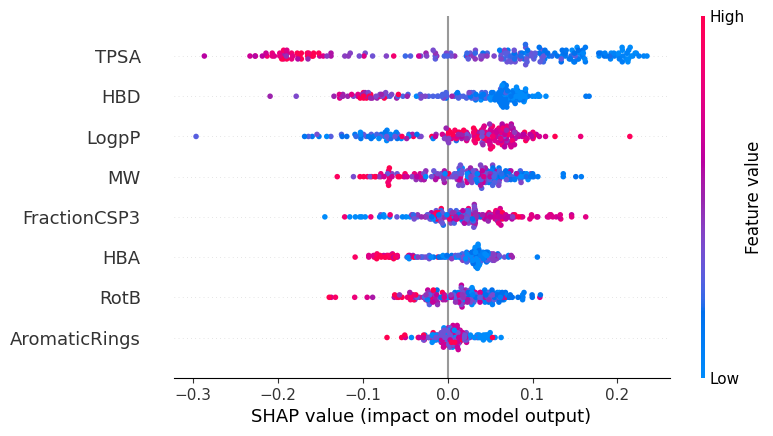

In [ ]:
# Select SHAP values for BBB+ predictions
shap_bbb = shap_values[:, :, 1]

# Generate SHAP beeswarm plot
shap.plots.beeswarm(shap_bbb, max_display=8)

In [ ]:
import pandas as pd
import numpy as np

shap_importance = pd.DataFrame({
    "Descriptor": X_shap.columns,
    "Mean_Absolute_SHAP":np.abs(
        shap_values.values[:, :, 1]
    ).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

print(shap_importance.to_string(index=False))

   Descriptor  Mean_Absolute_SHAP
         TPSA            0.127626
          HBD            0.066720
        LogpP            0.061789
           MW            0.050121
 FractionCSP3            0.043991
          HBA            0.040150
         RotB            0.038507
AromaticRings            0.016343


In [ ]:
from scipy.stats import spearmanr
import pandas as pd

shap_bbb_values = shap_values.values[:, :, 1]

direction_results = []

for i, descriptor in enumerate(X_shap.columns):

  correlation, p_value = spearmanr(
      X_shap[descriptor],
      shap_bbb_values[:, i]
  )

  direction_results.append({
      "Descriptor": descriptor,
      "Spearman r": round(correlation, 4),
      "P_value": p_value

  })

  direction_df = pd.DataFrame(direction_results)

  direction_df = direction_df.sort_values("Spearman_r")

  print(direction_df.to_string(index=False))


KeyError: 'Spearman_r'

In [ ]:
# Check whether the required variables exist

required_variables = [
    "X", "y", "X_train", "X_test", "y_train", "y_test"
]


for variable in required_variables:
  if variable in globals():
    obj = globals()[variable]
    print(f"{variable} available | shape = {getattr(obj, 'shape', 'N/a')}")
  else:
    print(f"{variable} NOT FOUND")
  print("\nExisting fitted model variables:")

  for name, obj in globals().copy().items():
    if hasattr(obj, "predict") and hasattr(obj, "fit"):
      print(f"{name}: {type(obj).__name__}")

X available | shape = (7805, 8)

Existing fitted model variables:
Pipeline: ABCMeta
LogisticRegression: type
model: Pipeline
RandomForestClassifier: ABCMeta
rf_model: RandomForestClassifier
y available | shape = (7805,)

Existing fitted model variables:
Pipeline: ABCMeta
LogisticRegression: type
model: Pipeline
RandomForestClassifier: ABCMeta
rf_model: RandomForestClassifier
X_train available | shape = (6244, 8)

Existing fitted model variables:
Pipeline: ABCMeta
LogisticRegression: type
model: Pipeline
RandomForestClassifier: ABCMeta
rf_model: RandomForestClassifier
X_test available | shape = (1561, 8)

Existing fitted model variables:
Pipeline: ABCMeta
LogisticRegression: type
model: Pipeline
RandomForestClassifier: ABCMeta
rf_model: RandomForestClassifier
y_train available | shape = (6244,)

Existing fitted model variables:
Pipeline: ABCMeta
LogisticRegression: type
model: Pipeline
RandomForestClassifier: ABCMeta
rf_model: RandomForestClassifier
y_test available | shape = (1561,)

E

In [ ]:
# RANDOM FOREST : CROSS-VALIDATION AND TEST EVALUATION

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import  (
    accuracy_score,
    roc_auc_score,
    classification_report,
    balanced_accuracy_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# 1. Encode BBB+ as 1 and BBB- as 0
# Also supports targets already encoded as 0 and 1.

def encode_bbb_target(values):
    s = pd.Series(values).reset_index(drop=True)

    if pd.api.types.is_numeric_dtype(s) or pd.api.types.is_bool_dtype(s):
       unique = set(s.dropna().unique())
       if unique.issubset({0,1,0.0,1.0, False, True}):
         return s.astype(int).to_numpy()

    labels = s.astype(str).str.strip().str.lower()

    positive = labels.str.fullmatch(
      r'bbb\s*\+|bbb[\s_-]*positive|positive|1|1\.0|true'
    )
    negative = labels.str.fullmatch(
      r'bbb\s*-|bbb[\s_-]*negative|negative|0|0\.0|false'
    )

    if (positive | negative).all() and positive.any() and negative.any():
      return positive.astype(int).to_numpy()

    raise ValueError(
      "Could not safely identify BBB+ and BBB- labels. "
      f"Observed labels: {s.unique()}"
    )


y_train_rf = encode_bbb_target(y_train)
y_test_rf = encode_bbb_target(y_test)

print("Training samples:", len(y_train_rf))
print("Test samples:", len(y_test_rf))
print("Training BBB+ proportion:", round(y_train_rf.mean(), 3))

# 2. Define Random Forest
rf_model_v2 = RandomForestClassifier(
      n_estimators=500,
      random_state=42,
      n_jobs=-1
)


# 3.  Stratified five-fold cross-validation on training data
cv = StratifiedKFold(
      n_splits=5,
      shuffle=True,
      random_state=42
)

scoring = {
      "ROC_AUC": "roc_auc",
      "Balanced_accuracy": "balanced_accuracy",
      "Average_precision": "average_precision",
      "PR_AUC": "average_precision",
      "Precision": "precision",
      "Recall": "recall",
      "F1": "f1"
}
cv_results = cross_validate(
      rf_model_v2,
      X_train,
      y_train_rf,
      cv=cv,
      scoring=scoring,
      n_jobs=-1,
      return_train_score=False

)

cv_summary = pd.DataFrame({
      "Metric": list(scoring.keys()),
      "Mean": [
          cv_results[f"test_{metric}"].mean()
          for metric in scoring
      ],
      "SD": [
          cv_results[f"test_{metric}"].std(ddof=1)
          for metric in scoring
      ]
})

print("\n=== FIVE-FOLD CROSS-VALIDATION ===")
print(cv_summary.round(4).to_string(index=False))

Training samples: 6244
Test samples: 1561
Training BBB+ proportion: 0.635

=== FIVE-FOLD CROSS-VALIDATION ===
           Metric   Mean     SD
          ROC_AUC 0.9440 0.0029
Balanced_accuracy 0.8462 0.0094
Average_precision 0.9652 0.0028
           PR_AUC 0.9652 0.0028
        Precision 0.8728 0.0073
           Recall 0.9276 0.0103
               F1 0.8994 0.0068


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# Gradient Boosting model
gb_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    random_state=42
)

# Five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "ROC_AUC": "roc_auc",
    "Balanced_accuracy": "balanced_accuracy",
    "Average_precision": "average_precision",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1"
}


gb_cv = cross_validate(
    gb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

results = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Mean": [
        gb_cv["test_"+ metric].mean() for metric in scoring
    ],
    "SD": [
        gb_cv["test_"+ metric].std() for metric in scoring
    ]
})

print("=== GRADIENT BOOSTING: FIVE-FOLD CROSS_VALIDATION ===")
print(results.round(4).to_string(index=False))

=== GRADIENT BOOSTING: FIVE-FOLD CROSS_VALIDATION ===
           Metric   Mean     SD
          ROC_AUC 0.9258 0.0058
Balanced_accuracy 0.8319 0.0107
Average_precision 0.9506 0.0051
        Precision 0.8607 0.0082
           Recall 0.9241 0.0050
               F1 0.8913 0.0066


In [ ]:
import pandas as pd
import numpy as np

# Use your existing training data
correlation_matrix = X_train.corr(method="spearman")

print("==== DESCRIPTOR CORRELATION MATRIX === ")
print(correlation_matrix.round(3).to_string())

# Identify strongly correlated descriptor pairs
pairs = []

columns = correlation_matrix.columns

for i in range(len(columns)):
    for j in range(i+1, len(columns)):

        correlation = correlation_matrix.iloc[i,j]


        pairs.append({
            "Descriptor_1": columns[i],
            "Descriptor_2": columns[j],
            "Spearman_r": correlation,
            "Absolute_r": abs(correlation)
        })

pairs_df = pd.DataFrame(pairs)

pairs_df = pairs_df.sort_values(
    "Absolute_r",
    ascending=False

)

print("\n=== TOP 10 STRONGEST CORRELATIONS ===")
print(
    pairs_df[
        ["Descriptor_1", "Descriptor_2", "Spearman_r"]
    ].head(10).round(3).to_string(index=False)

)

==== DESCRIPTOR CORRELATION MATRIX === 
                  MW  LogpP   TPSA    HBD    HBA   RotB  AromaticRings  FractionCSP3
MW             1.000  0.191  0.643  0.372  0.758  0.574          0.123         0.168
LogpP          0.191  1.000 -0.461 -0.492 -0.308  0.067          0.332        -0.092
TPSA           0.643 -0.461  1.000  0.758  0.895  0.441         -0.118         0.155
HBD            0.372 -0.492  0.758  1.000  0.584  0.270         -0.136         0.134
HBA            0.758 -0.308  0.895  0.584  1.000  0.510         -0.034         0.188
RotB           0.574  0.067  0.441  0.270  0.510  1.000          0.198         0.047
AromaticRings  0.123  0.332 -0.118 -0.136 -0.034  0.198          1.000        -0.747
FractionCSP3   0.168 -0.092  0.155  0.134  0.188  0.047         -0.747         1.000

=== TOP 10 STRONGEST CORRELATIONS ===
 Descriptor_1 Descriptor_2  Spearman_r
         TPSA          HBA       0.895
         TPSA          HBD       0.758
           MW          HBA       0.758


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)

import pandas as pd

# Fit Gradient Boosting on the training data
gb_model.fit(X_train, y_train)

# Model already trained earkier
models = {
    "Logistic Regression": model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

comparison = []

for name, clf in models.items():

  predictions = clf.predict(X_test)
  probabilities = clf.predict_proba(X_test)[:, 1]

  tn, fp, fn, tp = confusion_matrix(
      y_test, predictions, labels=[0,1]
  ).ravel()

  comparison.append({
      "Model": name,
      "Accuracy": accuracy_score(y_test, predictions),
      "Balanced_Accuracy": balanced_accuracy_score(
          y_test, predictions
      ),
      "ROC_AUC": roc_auc_score(y_test, probabilities),
      "Precision_BBB+": precision_score(
          y_test, predictions
      ),
      "Recall_BBB+": recall_score(
          y_test, predictions
      ),
      "Recall_BBB-": tn / (tn + fp),
      "F1_BBB+": f1_score(y_test, predictions),
      "MCC": matthews_corrcoef(y_test, predictions),
      "TN": tn,
      "FP": fp,
      "FN": fn,
      "TP": tp

  })

  comparison_df = pd.DataFrame(comparison)

  print("=== HELD-OUT TEST SET: MODEL COMPARISON ===")
  print(comparison_df.round(4).to_string(index=False))

=== HELD-OUT TEST SET: MODEL COMPARISON ===
              Model  Accuracy  Balanced_Accuracy  ROC_AUC  Precision_BBB+  Recall_BBB+  Recall_BBB-  F1_BBB+   MCC  TN  FP  FN  TP
Logistic Regression    0.8001             0.7561   0.8281           0.797       0.9193        0.593   0.8538 0.557 338 232  80 911
=== HELD-OUT TEST SET: MODEL COMPARISON ===
              Model  Accuracy  Balanced_Accuracy  ROC_AUC  Precision_BBB+  Recall_BBB+  Recall_BBB-  F1_BBB+    MCC  TN  FP  FN  TP
Logistic Regression    0.8001             0.7561   0.8281          0.7970       0.9193        0.593   0.8538 0.5570 338 232  80 911
      Random Forest    0.8757             0.8567   0.9507          0.8828       0.9273        0.786   0.9045 0.7287 448 122  72 919
=== HELD-OUT TEST SET: MODEL COMPARISON ===
              Model  Accuracy  Balanced_Accuracy  ROC_AUC  Precision_BBB+  Recall_BBB+  Recall_BBB-  F1_BBB+    MCC  TN  FP  FN  TP
Logistic Regression    0.8001             0.7561   0.8281          0.7970     

In [ ]:
# CROSS-MODEL ERROR ANALYSIS

import pandas as pd
import numpy as np

# Predictions from all three models
lr_pred = model.predict(X_test)
rf_pred = rf_model.predict(X_test)
gb_pred = gb_model.predict(X_test)

# Create error analysis table
error_df = X_test.copy()

error_df["Actual"] = np.asarray(y_test)

error_df["LR_Pred"] = lr_pred
error_df["RF_Pred"] = rf_pred
error_df["GB_Pred"] = gb_pred

# Identify incorrect predictions
error_df["LR_Error"] = (
    error_df["LR_Pred"] != error_df["Actual"]
).astype(int)

error_df["RF_Error"] = (
    error_df["RF_Pred"] != error_df["Actual"]
).astype(int)

error_df["GB_Error"] = (
    error_df["GB_Pred"] != error_df["Actual"]
).astype(int)

# Count models making errors
error_df["Error_Count"] = (
    error_df["LR_Error"] + error_df["RF_Error"] + error_df["GB_Error"]
)

# Add compound names and SMILES
error_df["compound_name"] = model_data.loc[
    X_test.index, "compound_name"
].values

error_df["SMILES"] = model_data.loc[
    X_test.index, "SMILES"
].values

print("==== ERROR AGREEMENT BETWEEN MODELS ===")

print(
    error_df["Error_Count"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\n=== COMPOUNDS MISCLASSIFIED BY ALL THREE MODELS ===")

shared_errors = error_df[
    error_df["Error_Count"] == 3
]

print("Total shared errors:", len(shared_errors))

columns = [
    "compound_name",
    "Actual",
    "LR_Pred",
    "RF_Pred",
    "GB_Pred",
    "MW",
    "LogpP",
    "TPSA",
    "HBD",
    "HBA"
]

print(
    shared_errors[columns]
    .head(15)
    .to_string(index=False)
)



==== ERROR AGREEMENT BETWEEN MODELS ===
Error_Count
0    1165
1     181
2      92
3     123

=== COMPOUNDS MISCLASSIFIED BY ALL THREE MODELS ===
Total shared errors: 123
                                                                                                                                                                                                      compound_name  Actual  LR_Pred  RF_Pred  GB_Pred      MW   LogpP   TPSA  HBD  HBA
                                                                                                                                                                                                     (+/-)-pirmenol       0        1        1        1 338.495 4.36060  36.36  1.0  3.0
                                                                                                                                                                                                   (s)-bicalutamide       1        0        0        0 430.379 2.87958 107.26 

In [ ]:
# RANDOM FOREST ERROR SUBGROUP ANALYSIS

import numpy as np
import pandas as pd

# Use existing error analysis dataframe
subgroup_df = error_df.copy()

#Define preduction categories
conditions = [
    (subgroup_df["Actual"] == 0) & (subgroup_df["RF_Pred"] == 1),
    (subgroup_df["Actual"] == 0) & (subgroup_df["RF_Pred"] == 1),
    (subgroup_df["Actual"] == 1) & (subgroup_df["RF_Pred"] == 0),
    (subgroup_df["Actual"] == 1) & (subgroup_df["RF_Pred"] == 1)
]

labels = [
    "True Negative",
    "False Positive",
    "False Negative",
    "True Positive"
]

subgroup_df["RF_Group"] = np.select(
    conditions,
    labels,
    default="Unknown"
)

descriptors = [
    "MW", "LogpP", "TPSA", "HBD", "HBA","RotB","AromaticRings","FractionCSP3"
]

# Count compounds in each group
print("=== RANDOM FOREST ERROR SUBGROUP COUNTS ===")

print(
    subgroup_df["RF_Group"]
    .value_counts()
    .to_string()
)

# Median molecular properties
print("\n=== MEDIAN DESCRIPTOR VALUES BY GROUP ===")

median_table = (
    subgroup_df
    .groupby("RF_Group")[descriptors]
    .median()
    .round(3)
)

print(median_table.to_string())

# Compare shared errors
print("\n=== SHARED ERRORS: ACTUAL BBB CLASS ===")

print(
    subgroup_df.loc[
        subgroup_df["Error_Count"] ==3,
        "Actual"
    ]
    .value_counts()
    .rename(index={0: "BBB-", 1: "BBB+"})
    .to_string()
)

=== RANDOM FOREST ERROR SUBGROUP COUNTS ===
RF_Group
True Positive     919
Unknown           448
True Negative     122
False Negative     72

=== MEDIAN DESCRIPTOR VALUES BY GROUP ===
                     MW  LogpP    TPSA  HBD  HBA  RotB  AromaticRings  FractionCSP3
RF_Group                                                                           
False Negative  339.408  1.913   94.83  2.0  5.0   4.0            2.0         0.441
True Negative   325.434  2.777   69.39  1.0  4.0   5.0            1.0         0.429
True Positive   339.366  3.033   52.60  1.0  4.0   3.0            1.0         0.500
Unknown         453.502  1.027  146.27  3.0  8.0   6.0            1.0         0.495

=== SHARED ERRORS: ACTUAL BBB CLASS ===
Actual
BBB-    95
BBB+    28


In [ ]:
import numpy as np
import pandas as pd

subgroup_df = error_df.copy()

# Assign labels using actual and predicted classes
subgroup_df["RF_Group"] = "Unknown"

subgroup_df.loc[
    (subgroup_df["Actual"] == 0) &
    (subgroup_df["RF_Pred"] == 0),
    "RF_Group"
] = "True Negative"

subgroup_df.loc[
    (subgroup_df["Actual"] == 0) &
    (subgroup_df["RF_Pred"] == 1),
    "RF_Group"
] = "False Positive"


subgroup_df.loc[
    (subgroup_df["Actual"] == 1) &
    (subgroup_df["RF_Pred"] == 0),
    "RF_Group"
] = "False Negative"

subgroup_df.loc[
    (subgroup_df["Actual"] == 1) &
    (subgroup_df["RF_Pred"] == 1),
    "RF_Group"
] = "True Positive"

descriptors = [
    "MW", "LogpP", "TPSA", "HBD", "HBA","RotB","AromaticRings","FractionCSP3"
]

print("=== RANDOM FOREST ERROR SUBGROUP COUNTS ===")

print(
    subgroup_df["RF_Group"]
    .value_counts()
    .to_string()
)

print("\n=== CORRECTED MEDIAN DESCRPTORS ===")

print(
    subgroup_df
    .groupby("RF_Group")[descriptors]
    .median()
    .round(3)
    .to_string()

)

# Verify clasification
assert  (
    subgroup_df["RF_Group"]  != "Unknown"
).all(), "Some compounds remain unclasssified."

print("\nValidation passed: ALL compounds classified.")



=== RANDOM FOREST ERROR SUBGROUP COUNTS ===
RF_Group
True Positive     919
True Negative     448
False Positive    122
False Negative     72

=== CORRECTED MEDIAN DESCRPTORS ===
                     MW  LogpP    TPSA  HBD  HBA  RotB  AromaticRings  FractionCSP3
RF_Group                                                                           
False Negative  339.408  1.913   94.83  2.0  5.0   4.0            2.0         0.441
False Positive  325.434  2.777   69.39  1.0  4.0   5.0            1.0         0.429
True Negative   453.502  1.027  146.27  3.0  8.0   6.0            1.0         0.495
True Positive   339.366  3.033   52.60  1.0  4.0   3.0            1.0         0.500

Validation passed: ALL compounds classified.


In [ ]:
# RANDOM FOREST: CONFIDENT PREDICTION ERRORS

import numpy as np
import pandas as pd

confidence_df = subgroup_df.copy()

# Probability of BBB+ classification
confidence_df["RF_Prob_BBB+"] = rf_model.predict_proba(
    X_test
)[:, 1]

#Probability assigned to the predicted class
confidence_df["Prediction_Confidence"] = np.where(
    confidence_df["RF_Pred"] == 1,
    confidence_df["RF_Prob_BBB+"],
    1 - confidence_df["RF_Prob_BBB+"]
)

# Keep incorrectly classified compounds
incorrect = confidence_df[
    confidence_df["RF_Group"].isin([
        "False Negative",
        "False Positive"
    ])
].copy()

# Sort by prediction confidence
incorrect = incorrect.sort_values(
    "Prediction_Confidence",
    ascending=False
)

print("=== RANDOM ROREST ERROR CONFIDENCE ===")

print("Total errors:", len(incorrect))

print(
    "Errors with confidence  >= 0.90:",
    (incorrect["Prediction_Confidence"]  >= 0.90).sum()
)

print(
    "Errors with confidence  >= 0.95:",
    (incorrect["Prediction_Confidence"]  >= 0.95).sum()
)

print("\n=== TOP 15 MOST CONFIDENT ERRORS ===")

columns =  [
    "compound_name",
    "Actual",
    "RF_Pred",
    "MW",
    "LogpP",
    "TPSA",
    "HBD",
    "HBA",
    "Prediction_Confidence"
]

print(
    incorrect[columns]
    .head(15)
    .round(4)
    .to_string(index=False)

)



=== RANDOM ROREST ERROR CONFIDENCE ===
Total errors: 194
Errors with confidence  >= 0.90: 22
Errors with confidence  >= 0.95: 10

=== TOP 15 MOST CONFIDENT ERRORS ===
                                      compound_name  Actual  RF_Pred       MW   LogpP   TPSA  HBD  HBA  Prediction_Confidence
                                                NaN       0        1  392.467  1.8957  94.83  3.0  5.0                 1.0000
                                                NaN       1        0  733.937  1.7856 193.91  5.0 14.0                 1.0000
                                         plicamycin       0        1 1085.156 -0.2493 358.20 11.0 24.0                 0.9967
                                      zinc100025275       0        1  275.348  1.8884  49.77  1.0  4.0                 0.9933
                                         clobutinol       0        1  255.789  2.8312  23.47  1.0  2.0                 0.9833
                                       smr000550494       1        0  416.518

In [ ]:
import pandas as pd
import numpy as np

# Verify original dataset labels against test labels
original_labels = (
    model_data.loc[X_test.index, "BBB+/BBB-"]
    .eq("BBB+")
    .astype(int)
)

print("=== LABEL ALIGNMENT CHECK ===")

print(
    "Test labels match original dataset:",
    np.array_equal(
        original_labels.to_numpy(),
        np.asarray(y_test)
    )
)

print("\n=== HIGH-CONFIDENCE ERROR RECORDS ===")

check_df = confidence_df[
    confidence_df["Prediction_Confidence"] >= 0.95
].copy()

check_df = check_df[
    check_df["RF_Group"].isin([
        "False Negative",
        "False Positive"
    ])
]

print(
    check_df[
        [
            "compound_name",
            "SMILES",
            "Actual",
            "RF_Pred",
            "RF_Prob_BBB+",
            "Prediction_Confidence"

        ]
    ].head(12).to_string(index=True)
)

print("\n=== DUPLICATE SMILES CHECK ===")

print(
    "Duplicate SMILES in test set:",
    confidence_df["SMILES"].duplicated().sum()
)

print(
    "Missing compound name:",
    confidence_df["compound_name"].isna().sum()
)

=== LABEL ALIGNMENT CHECK ===
Test labels match original dataset: True

=== HIGH-CONFIDENCE ERROR RECORDS ===
       compound_name                                                                                                                                                                                                                                                            SMILES  Actual  RF_Pred  RF_Prob_BBB+  Prediction_Confidence
3573             NaN                                                                                                                                                                                          C[C@H]1C[C@H]2[C@@H]3CCC4=CC(=O)C=CC4(C)C3(F)[C@@H](O)CC2(C)C1(O)C(=O)CO       0        1      1.000000               1.000000
5508      plicamycin  CO[C@H](C(=O)[C@@H](O)[C@@H](C)O)[C@@H]1Cc2cc3cc(O[C@H]4C[C@@H](O[C@H]5C[C@@H](O)[C@H](O)[C@@H](C)O5)[C@H](O)[C@@H](C)O4)c(C)c(O)c3c(O)c2C(=O)[C@H]1O[C@H]1C[C@@H](O[C@H]2C[C@@H](O[C@H]3C[C@](C)(O)[C@H](

In [ ]:
# Molecular SCAFFOLD GENERATION

import pandas as pd
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

scaffold_df = model_data.copy()

def get_scaffold(smiles):
    if pd.isna(smiles):
      return None

    mol = Chem.MolFromSmiles(str(smiles))

    if mol is None:
      return None

    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol,
        includeChirality=False
    )

scaffold_df["Scaffold"] = scaffold_df["SMILES"].apply(
    get_scaffold
)

print("=== MOLECULAR SCAFFOLD SUMMARY ===")

print("Total compounds:", len(scaffold_df))

print(
    "Valid scaffolds:",
    scaffold_df["Scaffold"].notna().sum()
)

print(
    "Unique scaffolds:",
    scaffold_df["Scaffold"].nunique()
)

print(
    "Acyclic compounds (empty scaffold):",
     (scaffold_df["Scaffold"] == "").sum()
)

print(
    "Invalid or missing structures:",
    scaffold_df["Scaffold"].isna().sum()
)

print("\n=== TOP 10 MOST COMMON SCAFFOLDS ===")

print(
    scaffold_df["Scaffold"]
    .value_counts()
    .head(10)
    .to_string()
)


=== MOLECULAR SCAFFOLD SUMMARY ===
Total compounds: 7805
Valid scaffolds: 7805
Unique scaffolds: 2129
Acyclic compounds (empty scaffold): 311
Invalid or missing structures: 0

=== TOP 10 MOST COMMON SCAFFOLDS ===
Scaffold
O=C1C=CC2C(=C1)CCC1C3CCCC3CCC21         410
c1ccccc1                                378
                                        311
O=C1C=C2CCC3C4CCCC4CCC3C2CC1            126
O=C1C=CC2C(=C1)CCC1C2CCC2C1CC1OCOC12    100
C1CCC(OC2CCCC(OC3CCCCO3)C2)OC1           59
N=C(C(=O)NC1C(=O)N2C=CCSC12)c1cscn1      55
c1ccc(Cc2ccccc2)cc1                      55
O=S(=O)(c1ccccc1)C1CC1c1ccccc1           55
O=C(Cc1ccccc1)NC1C(=O)N2CCSC12           51


In [ ]:
# SCAFFOLD-BASED TRAIN?TEST SPLIT

import numpy as np
from sklearn.model_selection import GroupShuffleSplit

# Same eight descriptors used previously
features = [
    "MW", "LogpP", "TPSA", "HBD", "HBA","RotB","AromaticRings","FractionCSP3"
]

X_scaffold = scaffold_df[features]

y_scaffold = (
    scaffold_df["BBB+/BBB-"] == "BBB+"
).astype(int)

groups = scaffold_df["Scaffold"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        X_scaffold,
        y_scaffold,
        groups=groups
    )
)

X_scaf_train = X_scaffold.iloc[train_idx]
X_scaf_test = X_scaffold.iloc[test_idx]

y_scaf_train = y_scaffold.iloc[train_idx]
y_scaf_test = y_scaffold.iloc[test_idx]

train_scaffolds = set(groups.iloc[train_idx])
test_scaffolds = set(groups.iloc[test_idx])

overlap = train_scaffolds.intersection(
    test_scaffolds
)

print("=== SCAFFOLD SPLIT SUMMARY ===")

print("Training compounds:", len(X_scaf_train))
print("Test compounds:", len(X_scaf_test))

=== SCAFFOLD SPLIT SUMMARY ===
Training compounds: 6382
Test compounds: 1423


In [ ]:
# SCAFFOLD-BASED MODEL EVALUATION

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix
)
import pandas as pd

scaffold_models = {
    "Logistic Regression": clone(model),
    "Random Forest": clone(rf_model),
    "Gradient Boosting": clone(gb_model)
}

scaffold_results = []

for name, clf in scaffold_models.items():

  clf.fit(X_scaf_train, y_scaf_train)

  predictions = clf.predict(X_scaf_test)
  probabilities = clf.predict_proba(X_scaf_test)[:, 1]

  tn, fp, fn, tp = confusion_matrix(
      y_scaf_test, predictions, labels=[0,1]
  ).ravel()

  scaffold_results.append({
      "Model": name,
      "Accuracy": accuracy_score(y_scaf_test, predictions),
      "Balanced_Accuracy": balanced_accuracy_score(
          y_scaf_test,predictions
      ),
      "ROC_AUC": roc_auc_score(y_scaf_test, probabilities),
      "MCC": matthews_corrcoef(y_scaf_test, predictions),
      "TN": tn,
      "FP": fp,
      "FN": fn,
      "TP": tp
  })

  scaffold_results_df = pd.DataFrame(scaffold_results)

  print("=== SCAFFOLD-BASED MODEL PERFORMANCE ===")
  print(scaffold_results_df.round(4).to_string(index=False))

  print("\n=== SCAFFOLD TEST CLASS DISTRIBUTION ===")
  print(y_scaf_test.value_counts().sort_index().to_string())

  print("\n=== SCAFFOLD OVERLAP CHECK ===")
  print("Shared scaffolds:", len(overlap))

=== SCAFFOLD-BASED MODEL PERFORMANCE ===
              Model  Accuracy  Balanced_Accuracy  ROC_AUC    MCC  TN  FP  FN  TP
Logistic Regression    0.7716             0.7507   0.8379 0.5392 365 254  71 733

=== SCAFFOLD TEST CLASS DISTRIBUTION ===
BBB+/BBB-
0    619
1    804

=== SCAFFOLD OVERLAP CHECK ===
Shared scaffolds: 0
=== SCAFFOLD-BASED MODEL PERFORMANCE ===
              Model  Accuracy  Balanced_Accuracy  ROC_AUC    MCC  TN  FP  FN  TP
Logistic Regression    0.7716             0.7507   0.8379 0.5392 365 254  71 733
      Random Forest    0.8173             0.8089   0.8880 0.6264 461 158 102 702

=== SCAFFOLD TEST CLASS DISTRIBUTION ===
BBB+/BBB-
0    619
1    804

=== SCAFFOLD OVERLAP CHECK ===
Shared scaffolds: 0
=== SCAFFOLD-BASED MODEL PERFORMANCE ===
              Model  Accuracy  Balanced_Accuracy  ROC_AUC    MCC  TN  FP  FN  TP
Logistic Regression    0.7716             0.7507   0.8379 0.5392 365 254  71 733
      Random Forest    0.8173             0.8089   0.8880 0.6264 4

In [ ]:
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs
import numpy as np

#  Generate radius-2 morgan fingerprints with 2048 bits
morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpsize=2048
)

molecules = [Chem.MolFromSmiles(s) for s in model_data["SMILES"]]
morgan_fps= [morgan_generator.GetFingerprint(mol) for mol in molecules]

# Convert fingerprints into a numerical matrix
X_morgan = np.zeros((len(morgan_fps), 2048), dtype=np.uint8)

for i, fp in enumerate(morgan_fps):
  DataStructs.ConvertToNumpyArray(fp, X[i])

  print("Fingerprint matrix shape", X_morgan.shape)
  print("Missing fingerprints:", sum(fp is None for fp in morgan_fps))

Fingerprint matrix shape: (7805, 2048)
Missing fingerprints: 0


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import  (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    matthews_corrcoef
)

X_morgan_train = X_morgan[train_idx]
X_morgan_test = X_morgan[test_idx]

morgan_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

morgan_rf.fit(X_morgan_train, y_scaf_train)

morgan_predictions = morgan_rf.predict(X_morgan_test)
morgan_probabilities = morgan_rf.predict_proba(X_morgan_test)[:,1]

morgan_results = {
    "Model": "Morgan Fingerprints + RF",
    "Accuracy": accuracy_score(y_scaf_test, morgan_predictions),
    "Balanced_Accuracy": balanced_accuracy_score(
        y_scaf_test, morgan_predictions
    ),
    "ROC_AUC": roc_auc_score(y_scaf_test, morgan_probabilities),
    "MCC": matthews_corrcoef(y_scaf_test, morgan_predictions)

}

print("Fingerprint-only model evaluation completed.")
print("Metrics saved in morgan_results.")


Fingerprint-only model evaluation completed.
Metrics saved in morgan_results.


In [ ]:
print ("Fingerprint variables:")
for name in ["X_fp", "X_train_fp", "X_test_fp",
             "rf_fp", "rf_fingerprint"]:
    print(name, name in globals())

Fingerprint variables:
X_fp False
X_train_fp False
X_test_fp False
rf_fp False
rf_fingerprint False


In [ ]:
print("Available variables:")
for name in ["X_train", "X_test", "X_train_scaled",
             "X_test_scaled", "y_train", "y_test",
             "train_idx", "test_idx", "X_train_fp",
             "X_test_fp"]:
    print(name, ":", name in globals())

Available variables:
X_train : True
X_test : True
X_train_scaled : False
X_test_scaled : False
y_train : True
y_test : True
train_idx : True
test_idx : True
X_train_fp : False
X_test_fp : False


In [ ]:
for name, obj in globals().copy().items():
    if hasattr(obj, "shape"):
       try:
         if len(obj.shape) == 2 and obj.shape[1] ==  2048:
              print(name, obj.shape)
       except:
           pass

X_morgan (7805, 2048)
X_morgan_train (6382, 2048)
X_morgan_test (1423, 2048)


In [ ]:
print("Fingerprint-related model variables:")

for name, obj in globals().copy().items():
    if any(word in name.lower() for word in ["morgan", "fingerprint", "fp"]):
       if hasattr(obj, "shape"):
           print(name, obj.shape)
       else:
           print(name,type(obj).__name__)

Fingerprint-related model variables:
fp ExplicitBitVect
rdFingerprintGenerator module
morgan_generator FingerprintGenerator64
morgan_fps list
X_morgan (7805, 2048)
X_morgan_train (6382, 2048)
X_morgan_test (1423, 2048)
morgan_rf RandomForestClassifier
morgan_predictions (1423,)
morgan_probabilities (1423,)
morgan_results dict


In [ ]:
print("MORGAN FINGERPRINT-ONLY MODEL RESULTS")

print(morgan_results)

print("\nPrediction distribution:")
print("Predictions:", morgan_predictions.shape)
print("Probabilities:", morgan_probabilities.shape)

MORGAN FINGERPRINT-ONLY MODEL RESULTS
{'Model': 'Morgan Fingerprints + RF', 'Accuracy': 0.8046380885453268, 'Balanced_Accuracy': np.float64(0.7927296072143322), 'ROC_AUC': np.float64(0.901742298202043), 'MCC': np.float64(0.6010501115833764)}

Prediction distribution:
Predictions: (1423,)
Probabilities: (1423,)


In [ ]:
import numpy as np

print("TRAIN/TEST SPLIT VERIFICATION")

print("Training indices:", len(train_idx))
print("Testing indices:", len(test_idx))

print("Training matrix matches:",
      np.array_equal(
          X_morgan_train,
          X_morgan[np.asarray(train_idx)]
      ))
print("Testing matrix matches:",
      np.array_equal(
          X_morgan_test,
          X_morgan[np.asarray(test_idx)]
      ))
print("Fingerprint list length:", len(morgan_fps))

TRAIN/TEST SPLIT VERIFICATION
Training indices: 6382
Testing indices: 1423
Training matrix matches: True
Testing matrix matches: True
Fingerprint list length: 7805


In [ ]:
from rdkit import DataStructs
import numpy as np

max_similarities = []

for test_fp in [morgan_fps[i] for i in test_idx]:

  similarities = DataStructs.BulkTanimotoSimilarity(
      test_fp,
      [morgan_fps[i] for i in train_idx]
  )

  max_similarities.append(max(similarities))

max_similarities = np.array(max_similarities)

print("APPLICABILITY DOMAIN ANALYSIS")
print("Test compounds:", len(max_similarities))
print("Mean maximum similarity:", round(np.mean(max_similarities),4))
print("Median maximum similarity:", round(np.median(max_similarities),4))
print("Minimum similarity:", round(np.min(max_similarities),4))
print("Maximum similarity:", round(np.max(max_similarities), 4))

print("\nSimilarity distribution:")
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    count = np.sum(max_similarities >= threshold)
    print(f">= {threshold}: {count} ({count/len(max_similarities)*100:.2f}%)")

APPLICABILITY DOMAIN ANALYSIS
Test compounds: 1423
Mean maximum similarity: 0.5138
Median maximum similarity: 0.5217
Minimum similarity: 0.125
Maximum similarity: 1.0

Similarity distribution:
>= 0.3: 1228 (86.30%)
>= 0.4: 1021 (71.75%)
>= 0.5: 786 (55.24%)
>= 0.6: 506 (35.56%)
>= 0.7: 184 (12.93%)


In [ ]:
import pandas as pd
import numpy as np

ad_results = pd.DataFrame({
    "Similarity": max_similarities,
    "Actual": np.asarray(y)[np.asarray(test_idx)],
    "Predicted": morgan_predictions
})

ad_results["Correct"] = (
    ad_results["Actual"] == ad_results["Predicted"]
)

ad_results["Similarity_Group"] = pd.cut(
    ad_results["Similarity"],
    bins=[-0.001, 0.3, 0.5, 0.7, 1.001],
    labels=["Low (<0.3)","Moderate (0.3-0.5)",
            "High (0.5-0.7)", "Very high (>=0.7)"]
)

summary = ad_results.groupby(
    "Similarity_Group", observed=False
).agg(
    Compounds=("Correct", "count"),
    Correct=("Correct", "sum"),
    Accuracy=("Correct", "mean")

)

summary["Accuracy"] = summary["Accuracy"].round(4)

print("PREDICTED PERFORMANCE BY STRUCTURAL SIMILARITY")
print(summary)

print("\nExact maximum fingerprint matches:",
      np.sum(max_similarities == 1.0))

PREDICTED PERFORMANCE BY STRUCTURAL SIMILARITY
                    Compounds  Correct  Accuracy
Similarity_Group                                
Low (<0.3)                197      125    0.6345
Moderate (0.3-0.5)        454      337    0.7423
High (0.5-0.7)            597      523    0.8760
Very high (>=0.7)         175      160    0.9143

Exact maximum fingerprint matches: 3


In [ ]:
from sklearn.metrics import balanced_accuracy_score

group_metrics = ad_results.groupby(
    "Similarity_Group", observed=False
).apply(
    lambda g: pd.Series({
        "Compounds": len(g),
        "BBB_negative": (g["Actual"] == 0).sum(),
        "BBB_positive": (g["Actual"] == 1).sum(),
        "Accuracy": g["Correct"].mean(),
        "Balanced_Accuracy": balanced_accuracy_score(
            g["Actual"], g["Predicted"]
        )
    }),
    include_groups=False
)

print("CLASS-ADJUSTED PERFORMANCE BY SIMILARITY")
print(group_metrics.round(4))

CLASS-ADJUSTED PERFORMANCE BY SIMILARITY
                    Compounds  BBB_negative  BBB_positive  Accuracy  \
Similarity_Group                                                      
Low (<0.3)              197.0          86.0         111.0    0.6345   
Moderate (0.3-0.5)      454.0         162.0         292.0    0.7423   
High (0.5-0.7)          597.0         254.0         343.0    0.8760   
Very high (>=0.7)       175.0         117.0          58.0    0.9143   

                    Balanced_Accuracy  
Similarity_Group                       
Low (<0.3)                     0.6010  
Moderate (0.3-0.5)             0.6911  
High (0.5-0.7)                 0.8702  
Very high (>=0.7)              0.8968  


In [ ]:
comparison = pd.DataFrame([
    {
        "Model": "Descriptor + Logistic Regression",
        "Accuracy": 0.7716,
        "Balanced_Accuracy": 0.7507,
        "ROC_AUC": 0.8379,
        "MCC": 0.5392
    },
    {
        "Model": "Descriptor + Random Forest",
        "Accuracy": 0.8173,
        "Balanced_Accuracy": 0.8089,
        "ROC_AUC": 0.8880,
        "MCC": 0.6264

    },
    {
        "Model": "Descriptor + Gradient Boosting",
        "Accuracy": 0.7948,
        "Balanced_Accuracy": 0.7864,
        "ROC_AUC": 0.8780,
        "MCC": 0.5801
    },
    {
        "Model": "Morgan Fingerprints + Random Forest",
        "Accuracy": 0.8046,
        "Balanced_Accuracy": 0.7927,
        "ROC_AUC": 0.9017,
        "MCC": 0.6011
    }
])

print("FINAL MODEL COMPARISON")
print(comparison.to_string(index=False))

print("\nBEST MODEL BY METRIC")
for metric in ["Accuracy", "Balanced_Accuracy", "ROC_AUC", "MCC"]:
    best = comparison.loc[comparison[metric].idxmax()]
    print(f"{metric}: {best['Model']} ({best[metric]:.4f})")

FINAL MODEL COMPARISON
                              Model  Accuracy  Balanced_Accuracy  ROC_AUC    MCC
   Descriptor + Logistic Regression    0.7716             0.7507   0.8379 0.5392
         Descriptor + Random Forest    0.8173             0.8089   0.8880 0.6264
     Descriptor + Gradient Boosting    0.7948             0.7864   0.8780 0.5801
Morgan Fingerprints + Random Forest    0.8046             0.7927   0.9017 0.6011

BEST MODEL BY METRIC
Accuracy: Descriptor + Random Forest (0.8173)
Balanced_Accuracy: Descriptor + Random Forest (0.8089)
ROC_AUC: Morgan Fingerprints + Random Forest (0.9017)
MCC: Descriptor + Random Forest (0.6264)


In [ ]:
print("DESCRIPTOR SPLIT VERIFICATION")

print("Descriptor training shape:", X_train.shape)
print("Descriptor testing shape:", X_test.shape)

print("Morgan training shape:", X_morgan_train.shape)
print("Morgan testing shape:", X_morgan_test.shape)

print("\nOriginal descriptor matrics:")

for name, obj in globals().copy().items():
    if hasattr(obj, "shape"):
        try:
            if len(obj.shape) == 2 and obj.shape[0] ==  7805:
              if obj.shape[1]  != 2048:
                 print(name,obj.shape)
        except:
             pass


DESCRIPTOR SPLIT VERIFICATION
Descriptor training shape: (6244, 8)
Descriptor testing shape: (1561, 8)
Morgan training shape: (6382, 2048)
Morgan testing shape: (1423, 2048)

Original descriptor matrics:
model_data (7805, 20)
X (7805, 8)
scaffold_df (7805, 21)
X_scaffold (7805, 8)


In [ ]:
print("SEARCHING FOR SCAFFOLD DESCRIPTOE SPLITS")

for name, obj in globals().copy().items():
    if hasattr(obj, "shape"):
        try:
           shape = obj.shape

           if len(shape) == 2 and shape[1] == 8:
              print(name, shape)

           elif len(shape) == 1 and len(obj) in [6382, 1423]:
              print(name, shape)
        except:
            pass


SEARCHING FOR SCAFFOLD DESCRIPTOE SPLITS
X (7805, 8)
X_train (6244, 8)
X_test (1561, 8)
X_shap (200, 8)
shap_bbb (200, 8)
shap_bbb_values (200, 8)
correlation_matrix (8, 8)
predictions (1423,)
probabilities (1423,)
median_table (4, 8)
X_scaffold (7805, 8)
train_idx (6382,)
test_idx (1423,)
X_scaf_train (6382, 8)
X_scaf_test (1423, 8)
y_scaf_train (6382,)
y_scaf_test (1423,)
morgan_predictions (1423,)
morgan_probabilities (1423,)
max_similarities (1423,)


In [ ]:
print("SCAFFOLD SPLIT VERIFICATION")

print(
    "Training features match:",
    np.array_equal(X_scaf_train, X_scaffold[train_idx])
)

print(
    "Testing features match:",
    np.array_equal(X_scaf_test, X_scaffold[test_idx])

)

print(
    "Training labels match:",
    np.array_equal(y_scaf_train, np.asarray(y)[train_idx])
)

print(
    "Testing labels match:",
    np.array_equal(y_scaf_test, np.asarray(y)[test_idx])
)

SCAFFOLD SPLIT VERIFICATION
Training features match: True
Testing features match: True
Training labels match: True
Testing labels match: True
